In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Data Generation (1000 Customer)
np.random.seed(42)
n = 1000

df = pd.DataFrame({
    'Tenure_Months': np.random.randint(1, 72, n),
    'Monthly_Charges': np.round(np.random.uniform(20, 120, n), 2),
    'Total_Charges': np.round(np.random.uniform(100, 8000, n), 2),
    'Contract_Type': np.random.choice(['Month-to-month', 'One year', 'Two year'], n , p=[0.5, 0.3, 0.2]),
    'Internet_Service': np.random.choice(['DSL', 'Fiber optic', 'No'], n, p=[0.4, 0.4, 0.2]),
    'Tech_Support': np.random.choice(['Yes', 'No'], n, p=[0.3, 0.7])
})

# Target banate hain (Churn = 1 agar tenure kam hai aur monthly charges zyada hai)
# Thoda realistic logic lagate hain

churn_prob = 1 / (1 + np.exp(-( -2 + (60 - df['Tenure_Months']) * 0.1 + (df['Monthly_Charges'] - 50)*0.03 )))
df['Churn'] = np.random.binomial(1, churn_prob)

# Thoda missing value daal dete hain (real world feel)
df.loc[np.random.choice(df.index, 20, replace=False), 'Total_Charges'] = np.nan

print("Dataset Shape:", df.shape)
print(df.head())
print("\nChurn Distribution:")
print(df['Churn'].value_counts(normalize=True))

Dataset Shape: (1000, 7)
   Tenure_Months  Monthly_Charges  Total_Charges   Contract_Type  \
0             52           105.57        3271.81        One year   
1             15           103.02        6420.56        One year   
2             61            59.72        1711.88        One year   
3             21            86.81        4485.17  Month-to-month   
4             24            40.50            NaN        Two year   

  Internet_Service Tech_Support  Churn  
0      Fiber optic          Yes      1  
1      Fiber optic           No      1  
2      Fiber optic          Yes      0  
3      Fiber optic           No      1  
4               No          Yes      1  

Churn Distribution:
Churn
1    0.64
0    0.36
Name: proportion, dtype: float64


C:\Users\kprin\AppData\Local\Temp\ipykernel_12872\2117864801.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Churn', y='Tenure_Months', data=df, palette='Set2')
C:\Users\kprin\AppData\Local\Temp\ipykernel_12872\2117864801.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Churn', y='Monthly_Charges', data=df, palette='Set2')


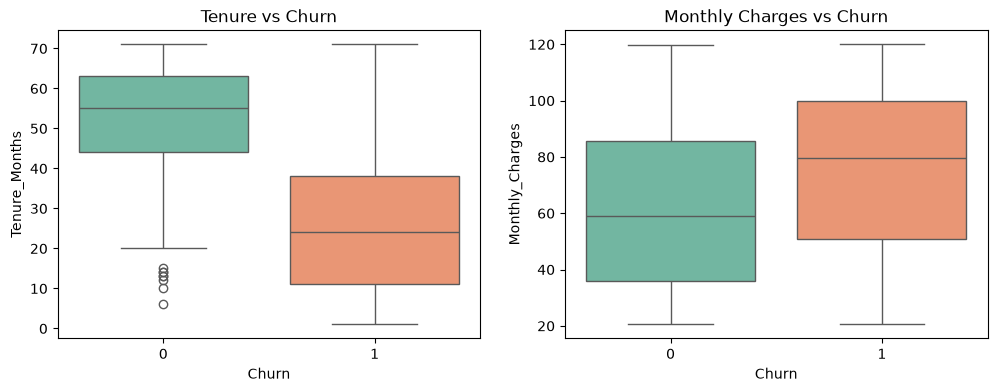

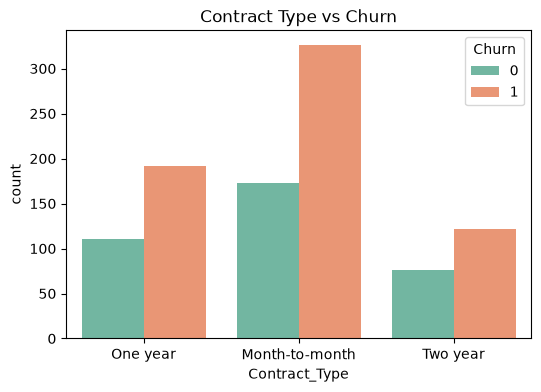

In [9]:
# 1. Tenure vs Churn
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.boxplot(x='Churn', y='Tenure_Months', data=df, palette='Set2')
plt.title("Tenure vs Churn")

# 2. Monthly Charges vs Churn
plt.subplot(1, 2, 2)
sns.boxplot(x='Churn', y='Monthly_Charges', data=df, palette='Set2')
plt.title("Monthly Charges vs Churn")

plt.show()

# 3. Contract Type vs Churn (Countplot)
plt.figure(figsize=(6, 4))
sns.countplot(x='Contract_Type', hue='Churn', data=df, palette='Set2')
plt.title("Contract Type vs Churn")
plt.show()

In [13]:
# 1. Features (X) aur Target (y) alag karo
X = df.drop('Churn', axis=1)
y = df['Churn']

# 2. Train-Test Split (80-20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Column types identify karo
num_cols = ['Tenure_Months', 'Monthly_Charges', 'Total_Charges']
cat_cols = ['Contract_Type', 'Internet_Service', 'Tech_Support']

# 4. Preprocessing setup (Missing values + Scaling + Encoding)
preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), num_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)
    ])

# 5. Model 1: Logistic Regression
log_reg_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

# 6. Model 2: Random Forest
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42))
])

# 7. Dono ko train karo
log_reg_pipeline.fit(X_train, y_train)
rf_pipeline.fit(X_train, y_train)

# 8. Predictions nikaalo
y_pred_log = log_reg_pipeline.predict(X_test)
y_pred_rf = rf_pipeline.predict(X_test)

# 9. Accuracy check karo
print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_log) * 100, "%")
print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf) * 100, "%")

Logistic Regression Accuracy: 83.0 %
Random Forest Accuracy: 82.0 %


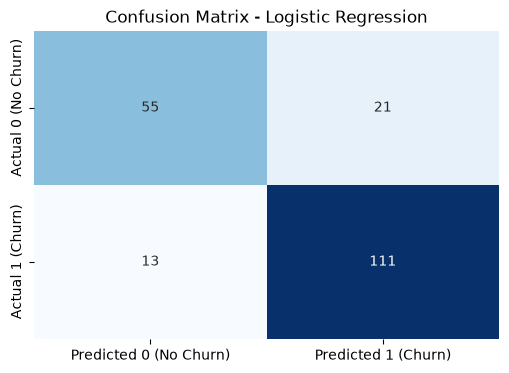

Classification Report:

              precision    recall  f1-score   support

           0       0.81      0.72      0.76        76
           1       0.84      0.90      0.87       124

    accuracy                           0.83       200
   macro avg       0.82      0.81      0.82       200
weighted avg       0.83      0.83      0.83       200



In [15]:
from sklearn.impute import SimpleImputer
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Confusion Matrix nikaalo
cm = confusion_matrix(y_test, y_pred_log)

# Visualize karo
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted 0 (No Churn)', 'Predicted 1 (Churn)'],
            yticklabels=['Actual 0 (No Churn)', 'Actual 1 (Churn)'])
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

# Classification Report
print("Classification Report:\n")
print(classification_report(y_test, y_pred_log))